# Grün ist nicht gleich Grün

Vegetationsanalyse mit Sentinel-2

# 1. Bibliotheken importieren

Am Anfang eines Moduls werden die Pakete importiert, die ihr benötigt.
Das ist wichtig, damit ihr zum Beispiel mit dem Paket `geolibre`eine
Karte erzeugen könnt.

In [ ]:
# Für Diagramme und Visualisierungen
import matplotlib.pyplot as plt
# Berechnungen durchführen
import numpy as np
# Für Betriebssystem-Funktionen (z.B. Dateipfade)
import os
# Zum Lesen/Schreiben von GeoTIFF-Dateien
import rasterio                    
# Interaktive Karte erstellen
import leafmap                     
# Für Geodaten-Visualisierung auf Karten
from geolibre import Map           

# 2. Vegetation in Berlin untersuchen

Für die Untersuchung von Klima und Klimawandel kann die Vegetation
herangezogen werden, denn Pflanzen reagieren direkt auf
Temperaturunterschiede und Trockenheit. Diese Reaktionen lassen sich
auch in Satellitenbildern messen. Um Vegetation zu untersuchen, müsst
ihr zuerst herausfinden, wo sie wächst. Das klingt einfach, aber
Vorsicht: Nicht alles, was wie Vegetation aussieht, ist tatsächlich
Vegetation. Dies wird am Beispiel einiger Sportplätze in Berlin genauer
betrachtet.

#### Aufgabe 1

Aktiviert die interaktive Karte und schaut euch in dem Kartenausschnitt
etwas um. Beschreibt, was ihr auf der Karte sehen könnt. Da es sich um
hochaufgelöste Aufnahmen handelt, könnt ihr sehr nah ranzoomen und somit
auch Details näher betrachten.

*(5 Minuten)*

In [ ]:
# Neue Karte konfigurieren mit Koordinaten und Zoomstufe; die Karte wird als Variable my_map gespeichert
my_map = leafmap.Map(center=[52.545154, 13.399177], zoom=15)

# Basemap hinzufügen
my_map.add_basemap("Esri.WorldImagery")

# Zuvor konfigurierte Karte aufrufen
my_map

Es sind Sportplätze sichtbar, die kräftig grün erscheinen, genauso wie
die vielen Bäume und Pflanzen drumherum. Beides sieht nach Vegetation
aus, doch einige der Plätze sind Kunstrasenplätze. Sie bestehen also
nicht aus echten Pflanzen. Für eine sichere Unterscheidung zwischen
echter Vegetation und Kunstrasen werden jedoch mehr Daten benötigt.

## 2.1 Echtfarbenbild

Damit ihr zwischen echter Vegetation und Kunstrasen unterscheiden könnt,
braucht ihr zunächst ein Echtfarbenbild. Hierfür werden Sentinel-2 Daten
genutzt. Achtet bei eurer Untersuchung auf einen passenden Zeitraum. Am
besten eignen sich Aufnahmen aus der Vegetationsperiode von März bis
September. Zu dieser Zeit wachsen und gedeihen Pflanzen. In unserem
Beispiel haben wir einen Zeitraum von Mai bis August gewählt.

In [ ]:
# Visualisierung RGB
with rasterio.open("./data/berlin_rgb_cog.tif") as src:
    rgb_data = src.read([1, 2, 3])                      # Sentinel-2 L2A Daten sind oft in DN (Digital Numbers) skaliert (0-10000)
    rgb_data = np.clip(rgb_data / 3000.0, 0, 1)         # Einfache Skalierung für die Anzeige (0-3000 als Bereich für bessere Kontraste)
    rgb_display = np.transpose(rgb_data, (1, 2, 0))     # Umordnen von (Bands, H, W) zu (H, W, Bands) für imshow

plt.figure(figsize=(10, 10))
plt.imshow(rgb_display)
plt.title("Echtfarben (True Color RGB) - Berlin")       # Titel der Grafik, kann von euch umbenannt werden
plt.axis("off")
plt.show()

Auf den ersten Blick sehen die Daten schlechter aus als bei der
interaktiven Karte. Dies liegt daran, dass ein Pixel nur noch eine
Fläche von 10m x 10m abbildet. Das heißt die **räumliche Auflösung** ist
geringer. Dadurch gehen Details verloren, doch Fußballplätze sind
weiterhin gut zu sehen.

Die Farben sehen ähnlich aus wie auf einem normalen Foto. Das liegt
daran, dass wir ein **Echtfarbenbild** (**RGB-Bild**) verwenden. RGB
steht für die Farben Rot, Grün und Blau. Jede Farbe wird einem
bestimmten Kanal zugeordnet. Bei Sentinel-2 sieht das so aus: Dem roten
Farbkanal (Band 4) wird das rote Licht zugeordnet. Dem grünen Kanal
(Band 3) wird das grüne Licht und dem blauen Kanal (Band 2) das blaue
Licht zugeordnet.

-   R = Rotes Licht (B4)
-   G = Grünes Licht (B3)
-   B = Blaues Licht (B2)

Bei Fotos auf dem Handy passiert das gleiche. Auch dort werden die
Farben Rot, Grün und Blau kombiniert. Mit Filtern könnt ihr die
Kanalkombination verändern, um mehr Kontrast oder besondere Farbeffekte
zu erzeugen.

## 2.2 Falschfarbenbild

Die RGB-Farben gehören zum sichtbaren Licht. Das ist der Teil des
Lichts, den wir mit unseren Augen sehen können. Satelliten wie
Sentinel-2 erfassen aber auch Licht, das für uns unsichtbar ist. Das
heißt, sie nehmen mehr Wellenlängenbereiche auf: z.B. infrarotes Licht
(bekannt von Fernbedienungen oder Wärmelampen), Mikrowellen (Radar) oder
Ultraviolett. Um dieses unsichtbare Licht für uns sichtbar zu machen,
kann es auf einen der drei Farbkanäle gelegt werden.

In der nächsten Codezelle wird erneut ein Satellitenbild geladen.
Diesmal verwenden wir andere Bereiche des reflektierten Lichts:

-   R = Infrarotes Licht (B8)
-   G = Rotes Licht (B4)
-   B = Grünes Licht (B3)

Ihr seht hier eine andere Farbkombination. Blaues Licht wird zwar nicht
mehr dargestellt, dafür aber Infrarot. Bei Sentinel-2 deckt Band 8
Wellenlängen des **nahen Infrarots** ab. Dadurch entsteht ein
sogenanntes **Falschfarbenbild**, auch **CIR-Bild** genannt
(Color-Infrared).

In [ ]:
# Visualisierung CIR
with rasterio.open("./data/berlin_cir_cog.tif") as src:
    cir_data = src.read([1, 2, 3])                      # Bänder 1, 2, 3 entsprechen hier B08, B04, B03
    cir_data = np.clip(cir_data / 3000.0, 0, 1)
    cir_display = np.transpose(cir_data, (1, 2, 0))

plt.figure(figsize=(10, 10))
plt.imshow(cir_display)
plt.title("Falschfarbenbild (CIR) - Berlin")
plt.axis("off")
plt.show()

## 2.3 Abgleich mit einer Landbedeckungsklassifikation

Damit ihr eure Vermutungen zum Kunstrasen überprüfen könnt, wird eine
Landbedeckungsklassifikation der europäischen Raumfahrtbehörde ESA
genutzt (ESA Worldcover 2020).

Hier seht ihr, wie eine solche Klassifikation für Berlin aussieht. Die
Naturrasenplätze werden gelb dargestellt, was der Klasse Grassland
(Grasflächen) entspricht. Die Kunstrasenplätze werden der Klasse
Built-up (Bebauung) zugeordnet. Dazu gehören nicht nur Gebäude, sondern
generell versiegelte bzw. künstliche Oberflächen wie Asphalt, Beton oder
Dachziegel. Auch Kunststoffbahnen auf Sportplätzen oder Kunstrasen
zählen dazu.

<figure>
<img src="images/CDEC_M1_Teil2_esa-wc-berlin.png"
alt="ESA World Cover Berlin" />
<figcaption aria-hidden="true">ESA World Cover Berlin</figcaption>
</figure>

[Bildquelle](https://esa-worldcover.org/en/data-access)

<figure>
<img src="images/CDEC_M1_Teil2_esa-wc-legend.png"
alt="ESA World Cover Legende" />
<figcaption aria-hidden="true">ESA World Cover Legende</figcaption>
</figure>

[Bildquelle](https://esa-worldcover.s3.eu-central-1.amazonaws.com/v100/2020/docs/WorldCover_PUM_V1.0.pdf)

| Farbcode / Darstellung | Name (Englisch) | Name (Deutsch) |
|----|----|----|
| **Dunkelgrün** | Tree cover | Baumbedeckung |
| **Orange** | Shrubland | Strauchvegetation |
| **Hellgelb** | Grassland | Grasland |
| **Rosa / Violett** | Cropland | Ackerland |
| **Rot** | Built-up | Bebaute Fläche |
| **Grau** | Bare / sparse vegetation | Karg / Spärliche Vegetation |
| **Weiß** | Snow and ice | Schnee / Eis |
| **Blau** | Permanent water bodies | Wasserflächen |
| **Türkis** | Herbaceous wetland | Feuchtgebiet |
| **Hellgrün** | Mangroves | Mangroven |
| **Khaki** | Moss and lichen | Moose / Flechten |

# 3. Vergleich der Satellitenbilder

Mit dem nachfolgenden Code werden die Bilder in eine interaktiven Karte
eingeladen und visualisiert. Wir nutzen diesmal nicht leafmap, sondern
*GeoLibre*, weil wir ein paar Funktionen benötigen, die leafmap nicht
hat. Wenn ihr den Code ausführt, öffnet sich eine interaktive Karte mit
einer Layer-Swipe Funktion (im Code auch *Split-Map* genannt). Die
Dateien werden automatisch in die Karte geladen. Ihr braucht nichts
weiter machen und könnt jetzt mit den Bildern interagieren.

> **Hinweis**
>
> Weitere Einstellungen für die Layer-Swipe Funktion sind im
> Kartenfenster über das “Pause-Zeichen” oben links zu erreichen.

#### Aufgabe 2

Nutzt den Slider in der Kartenmitte, um zwischen Echt- und
Falschfarbenbild hin- und herzublenden. Beobachtet, wie die Vegetation
anfängt rot zu leuchten. Wie viele Kunstrasenplätze entdeckt ihr im
angezeigten Bildausschnitt? Beschreibt, wie ihr die Kunstrasenplätze
identifiziert habt und vergleicht eure Ergebnisse mit der
Klassifikationskarte von Berlin.

*(15 Minuten)*

In [ ]:
# RGB, CIR und ESA Daten mit Geolibre in einer Karte visualisieren
m = Map(center=[13.400207, 52.542231], zoom=13)    # [Lon, Lat]

esa = m.add_cog("./data/berlin_esa_cog.tif", name="ESA")
rgb = m.add_cog("./data/berlin_rgb_cog.tif", name="RGB")
cir = m.add_cog("./data/berlin_cir_cog.tif", name="CIR")

# Aktivieren der Split-Map bzw. Layer-Swipe Funktion
m.split_map(rgb, cir)
m

Warum sehen Vegetation und Kunstrasenplätze im Echtfarbenbild beide grün
aus? Das liegt daran, dass beide Oberflächen grünes Licht reflektieren
und blaues/rotes Licht absorbieren. Das reflektierte Licht können wir
sehen. Bei Pflanzen ist Chlorophyll für die grüne Farbe verantwortlich,
bei Kunstrasen dagegen sind es grüne Farbpigmente.

Aber warum unterscheiden sie sich im Falschfarbenbild? Pflanzen
reflektieren infrarotes Licht sehr stark. Im Falschfarbenbild wird
Infrarot in der Farbe Rot dargestellt, deshalb leuchtet das Bild
plötzlich so rot. Versiegelte Flächen oder solche mit Erdboden, wie
Straßen oder abgeerntete Felder, reflektieren dieses Licht wiederrum
nicht und erscheinen dunkel.

So ist das übrigens auch bei gestresster Vegetation. Durch fehlendes
Chlorophyll reflektiert die Pflanze infrarotes Licht weniger stark.
Dieses Verhalten wird genutzt, um gesunde von geschwächter Vegetation zu
unterscheiden.

<figure>
<img src="images/CDEC_M1_Teil3_reflektanzkurven.jpg"
alt="Reflektanzkurve" />
<figcaption aria-hidden="true">Reflektanzkurve</figcaption>
</figure>

[Bildquelle](https://ai.hdm-stuttgart.de/news/2022/satellitendaten-verstehen-die-grundlagen/)

> **Zusammenfassung**
>
> -   **Echte, gesunde Vegetation**: Gesunde Pflanzen reflektieren nahes
>     Infrarot stark (bis zu 50–60 % der Strahlung), da sie Chlorophyll
>     enthalten.
> -   **Gestresste Vegetation**: Ist die Pflanze geschwächt, sinkt der
>     Chlorophyllgehalt und die Reflektion im Infrarotbereich wird
>     weniger.
> -   **Kunstrasen**: Plastik besitzt keine pflanzlichen Zellen. Es
>     reflektiert im nahen Infrarot kaum mehr als im sichtbaren Licht.
> -   **Asphalt / Beton**: Mineralische Oberflächen reflektieren
>     sichtbares Licht mittelstark, aber kein nahes Infrarot.

| Objekt | RGB \[B04, B03, B02\] | CIR \[B08, B04, B03\] |
|----|----|----|
| **Gesunde Vegetation** | grün | leuchtendes rot / magenta |
| **Gestresste Vegetation** | gelb bis braun | dunkelrot, braun |
| **Kunstrasen** | sattes grün | dunkelgrau, braun bis blau-schwarz |
| **Bäume & Sträucher** | dunkelgrün | kräftiges rot bis rosa |
| **Asphalt / Beton** | grau bis weiß | cyan, hellgrau bis bläulich |

# 4. Zusammenfassung

In diesem Notebook habt ihr gelernt:

-   was es mit Echt- und Falschfarbenbildern auf sich hat,
-   mithilfe eines Falschfarbenbildes Kunstrasen von echter Vegetation
    zu unterscheiden,
-   eure Vermutungen mit einer Klassifikationskarte zu bestätigen,
-   mit einer Layer-Swipe Funktion die verschiedenen Bildern zu
    vergleichen,
-   wie sich die Strahlungseigenschaften von verschiedenen Oberflächen
    verhalten
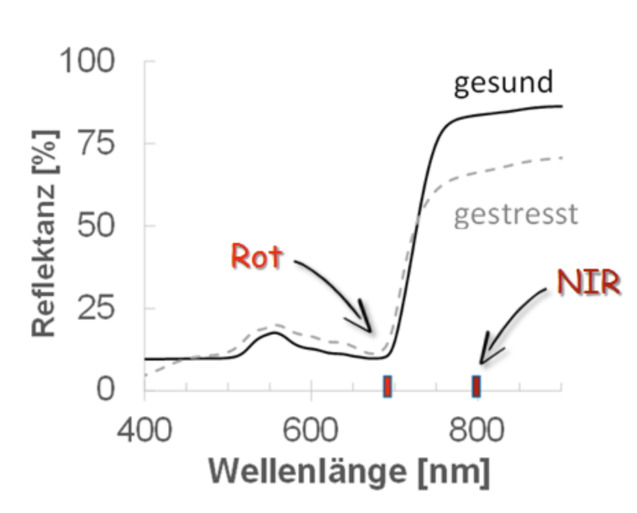